# Supplementary Figure S17 — saturation-pressure model comparisons

Standalone, function-free workflow comparing stored MagmaSat/MELTS saturation pressures with Liu et al. (2005) and VolatileCalc-Rhyolite calculations for the same 112 melt inclusions.

This notebook requires Python 3.11, `VESIcal==1.2.12`, and an internet connection. VolatileCalc is retrieved from its pinned GitHub source commit.

## Shared setup for Figure S17

In [1]:
from pathlib import Path
import importlib.metadata
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle
from matplotlib.path import Path as MarkerPath
from matplotlib.patches import Patch
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S17_Saturation_Pressure_Comparisons'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S17_Saturation_Pressure_Comparisons_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

WORKBOOK_PATHS = {
    'S1': DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx',
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 4.4
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300

PUBLICATION_FONT = 'Arial'
if PUBLICATION_FONT not in {entry.name for entry in font_manager.fontManager.ttflist}:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT, 'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT, 'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT, 'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 0.5,
    'lines.linewidth': 0.75, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

SAMPLE_ORDER = ['74D', '74A', '75', '76A']
SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
PHASE_LABELS = {'plag': 'Plagioclase-hosted MI', 'pxy': 'Pyroxene-hosted MI'}

# Approved marker geometry from 00_Setup.
MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0}
MARKER_LETTERS = {'plag': 'o', 'pxy': 's'}
MARKER_PATHS = {}
SCATTER_STYLES = {}

for category, marker in MARKER_LETTERS.items():
    standard_marker = MarkerStyle(marker)
    marker_path = standard_marker.get_path().transformed(standard_marker.get_transform())
    bounds = marker_path.get_extents()
    vertices = marker_path.vertices.copy()
    vertices[:, 0] = (vertices[:, 0] - (bounds.x0 + bounds.x1) / 2) / bounds.width
    vertices[:, 1] = (vertices[:, 1] - (bounds.y0 + bounds.y1) / 2) / bounds.height
    normalized_path = MarkerPath(vertices, marker_path.codes)
    MARKER_PATHS[category] = normalized_path
    SCATTER_STYLES[category] = {
        'marker': normalized_path,
        's': (MARKER_SPANS_PT[category] - MINIMUM_LINE_WIDTH_PT) ** 2,
        'linewidths': MINIMUM_LINE_WIDTH_PT,
        'edgecolors': 'black',
    }

print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S17_Saturation_Pressure_Comparisons
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 4.4 in


## Figure S17-specific data preparation

The shared setup ends above. This figure reads only Supplement 1, sheet `MI_Hosts_Plag_Pxy`. It retains the four Glacier Peak sample groups, melt inclusions only, complete saturation-pressure inputs, and the established SIMS and SEM exclusions. The same 112 inclusions are supplied to all three models.

In [2]:
SOURCE_SHEET = 'MI_Hosts_Plag_Pxy'
MELTS_PRESSURE_COLUMN = 'P_bar_SatP'
SATURATION_INPUT_COLUMNS = [
    'SiO2_Liq_SatP',
    'TiO2_Liq_SatP',
    'Al2O3_Liq_SatP',
    'FeOt_Liq_SatP',
    'MnO_Liq_SatP',
    'MgO_Liq_SatP',
    'CaO_Liq_SatP',
    'Na2O_Liq_SatP',
    'K2O_Liq_SatP',
    'P2O5_Liq_SatP',
    'H2O_Liq_SatP',
    'CO2_Liq_SatP',
]
SOURCE_COLUMNS = [
    'base_name',
    'mineral_phase',
    'Discard_SIMS',
    'Discard_SEMGlass_Raw',
    *SATURATION_INPUT_COLUMNS,
    MELTS_PRESSURE_COLUMN,
]

source = pd.read_excel(
    WORKBOOK_PATHS['S1'],
    sheet_name=SOURCE_SHEET,
    usecols=SOURCE_COLUMNS,
)

source['sample_key'] = source['base_name'].astype('string').str.extract(
    r'^(74D|74A|75|76A)',
    expand=False,
)
source['phase_key'] = source['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
source['is_melt_inclusion'] = source['base_name'].astype('string').str.contains(
    r'(?:^|_)MI\d',
    case=False,
    regex=True,
    na=False,
)
source['discard_sims'] = source['Discard_SIMS'].astype('string').str.strip().str.casefold().eq('yes').fillna(False)
source['discard_sem'] = source['Discard_SEMGlass_Raw'].astype('string').str.strip().str.casefold().str.startswith('yes', na=False)

for column in [*SATURATION_INPUT_COLUMNS, MELTS_PRESSURE_COLUMN]:
    source[column] = pd.to_numeric(source[column], errors='coerce').replace([np.inf, -np.inf], np.nan)

complete_inputs = source[[*SATURATION_INPUT_COLUMNS, MELTS_PRESSURE_COLUMN]].notna().all(axis=1)
retained_rows = (
    source['sample_key'].isin(SAMPLE_ORDER)
    & source['phase_key'].isin(['plag', 'pxy'])
    & source['is_melt_inclusion']
    & ~source['discard_sims']
    & ~source['discard_sem']
    & complete_inputs
)
population = source.loc[retained_rows].copy().reset_index(drop=True)

sample_counts = population['sample_key'].value_counts().reindex(SAMPLE_ORDER)
sem_excluded_names = source.loc[source['discard_sem'], 'base_name'].tolist()

print('Retained common population:', len(population))
print('Sample counts:', sample_counts.to_dict())
print('SEM-excluded inclusions:', sem_excluded_names)
print(
    'CO2_Liq_SatP range:',
    f"{population['CO2_Liq_SatP'].min():.6f}–{population['CO2_Liq_SatP'].max():.6f} wt%",
)

if len(population) != 112:
    raise ValueError('Expected the established common population of 112 melt inclusions.')
if sample_counts.to_dict() != {'74D': 22, '74A': 36, '75': 23, '76A': 31}:
    raise ValueError('The established S16 sample counts have changed.')
if set(sem_excluded_names) != {'74D_C48_MI1', '74A_C6_MI1', '74A_C23_MI3', '76A_C31_MI1'}:
    raise ValueError('The established SEM exclusion set has changed.')

Retained common population: 112
Sample counts: {'74D': 22, '74A': 36, '75': 23, '76A': 31}
SEM-excluded inclusions: ['74A_C23_MI3', '74A_C6_MI1', '74D_C48_MI1', '76A_C31_MI1']
CO2_Liq_SatP range: 0.003087–0.061257 wt%


## Saturation-pressure calculations

MagmaSat/MELTS pressures are read from the stored `P_bar_SatP` field and are not recalculated. Liu et al. (2005) pressures are calculated through VESIcal 1.2.12 at 900 °C. VolatileCalc uses the rhyolite composition option at 900 °C and is downloaded from its pinned GitHub source commit.

In [3]:
MODEL_TEMPERATURE_C = 900.0
VOLATILECALC_SOURCE_URL = (
    'https://raw.githubusercontent.com/DJRgeoscience/'
    'VolatileCalcForPython/2ba5fd1bbd82048a288ac4df1940a6a8ff03fd7e/'
    'VolatileCalc.py'
)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    import VESIcal as vesical

vesical_version = importlib.metadata.version('VESIcal')
if vesical_version != '1.2.12':
    raise RuntimeError(f'S16 requires VESIcal 1.2.12; installed version is {vesical_version}.')

vesical_column_map = {
    'SiO2_Liq_SatP': 'SiO2',
    'TiO2_Liq_SatP': 'TiO2',
    'Al2O3_Liq_SatP': 'Al2O3',
    'FeOt_Liq_SatP': 'FeO',
    'MnO_Liq_SatP': 'MnO',
    'MgO_Liq_SatP': 'MgO',
    'CaO_Liq_SatP': 'CaO',
    'Na2O_Liq_SatP': 'Na2O',
    'K2O_Liq_SatP': 'K2O',
    'P2O5_Liq_SatP': 'P2O5',
    'H2O_Liq_SatP': 'H2O',
    'CO2_Liq_SatP': 'CO2',
}
vesical_input = population[list(vesical_column_map)].rename(columns=vesical_column_map).copy()
vesical_input.index = pd.RangeIndex(len(vesical_input), name='row_id')

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    liu_output = vesical.BatchFile_from_DataFrame(
        vesical_input,
        units='wtpt_oxides',
    ).calculate_saturation_pressure(
        temperature=MODEL_TEMPERATURE_C,
        model='Liu',
        print_status=False,
    )

volatilecalc_source = urllib.request.urlopen(
    VOLATILECALC_SOURCE_URL,
    timeout=30,
).read()
volatilecalc_text = volatilecalc_source.decode('utf-8')
if not volatilecalc_text.endswith('\n'):
    volatilecalc_text += '\n'

with warnings.catch_warnings():
    warnings.simplefilter('ignore', DeprecationWarning)
    from lib2to3.refactor import RefactoringTool, get_fixers_from_package

    conversion_tool = RefactoringTool(get_fixers_from_package('lib2to3.fixes'))
    volatilecalc_python3 = str(
        conversion_tool.refactor_string(volatilecalc_text, 'VolatileCalc.py')
    )

volatilecalc_namespace = {}
exec(
    compile(volatilecalc_python3, 'VolatileCalc.py', 'exec'),
    volatilecalc_namespace,
)
volatilecalc_calculation = volatilecalc_namespace['VolatileCalc']

results = population[
    ['base_name', 'sample_key', 'phase_key', MELTS_PRESSURE_COLUMN]
].copy()
results['P_bar_MELTS_v1_2_0'] = population[MELTS_PRESSURE_COLUMN]
results['P_bar_Liu_2005'] = pd.to_numeric(
    liu_output['SaturationP_bars_VESIcal'],
    errors='coerce',
).to_numpy()

volatilecalc_pressures_bar = []
for row in population.itertuples(index=False):
    co2_ppm = float(row.CO2_Liq_SatP) * 10000
    output, model_warnings = volatilecalc_calculation(
        'sp',
        'rhyolite',
        [float(row.H2O_Liq_SatP), co2_ppm, MODEL_TEMPERATURE_C],
    )
    volatilecalc_pressures_bar.append(float(output[0]) * 10)

results['P_bar_VolatileCalc_Rhyolite'] = volatilecalc_pressures_bar

PRESSURE_COLUMNS = [
    'P_bar_MELTS_v1_2_0',
    'P_bar_Liu_2005',
    'P_bar_VolatileCalc_Rhyolite',
]
if not np.isfinite(results[PRESSURE_COLUMNS].to_numpy()).all():
    raise ValueError('At least one saturation-pressure calculation failed.')

diagnostic_rows = []
for model_name, pressure_column in [
    ('Liu et al. (2005)', 'P_bar_Liu_2005'),
    ('VolatileCalc-Rhyolite', 'P_bar_VolatileCalc_Rhyolite'),
]:
    pressure_difference_bar = (
        results[pressure_column] - results['P_bar_MELTS_v1_2_0']
    )
    diagnostic_rows.append({
        'model': model_name,
        'n': len(pressure_difference_bar),
        'median difference (MPa)': pressure_difference_bar.median() * 0.1,
        'mean difference (MPa)': pressure_difference_bar.mean() * 0.1,
        'fraction above 1:1': pressure_difference_bar.gt(0).mean(),
    })

diagnostics = pd.DataFrame(diagnostic_rows)
print('VESIcal version:', vesical_version)
print('VolatileCalc source:', VOLATILECALC_SOURCE_URL)
display(diagnostics.round(3))

VESIcal version: 1.2.12
VolatileCalc source: https://raw.githubusercontent.com/DJRgeoscience/VolatileCalcForPython/2ba5fd1bbd82048a288ac4df1940a6a8ff03fd7e/VolatileCalc.py


,model,n,median difference (MPa),mean difference (MPa),fraction above 1:1
0,Liu et al. (2005),112,22.074,22.326,1.0
1,VolatileCalc-Rhyolite,112,18.594,17.901,1.0


## Plot and export Figure S17

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S17_Saturation_Pressure_Comparisons/Figure_S17_Saturation_Pressure_Comparisons_Final/Figure_S17_SaturationPressure_Model_Agreement.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S17_Saturation_Pressure_Comparisons/Figure_S17_Saturation_Pressure_Comparisons_Final/Figure_S17_SaturationPressure_Model_Agreement.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S17_Saturation_Pressure_Comparisons/Figure_S17_Saturation_Pressure_Comparisons_Final/Figure_S17_SaturationPressure_Model_Agreement.svg


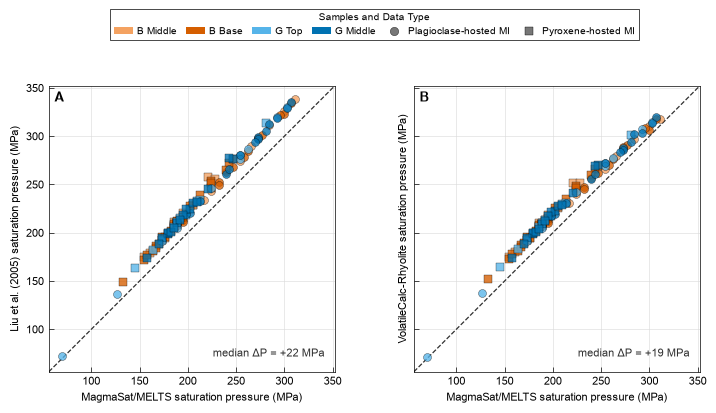

In [4]:
# VESIcal changes Matplotlib settings during import, so restore the publication typography here.
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT, 'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT, 'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT, 'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT, 'axes.linewidth': 0.5,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

BAR_TO_MPA = 0.1
all_pressures_mpa = results[PRESSURE_COLUMNS].to_numpy().ravel() * BAR_TO_MPA
pressure_minimum = float(all_pressures_mpa.min())
pressure_maximum = float(all_pressures_mpa.max())
pressure_padding = 0.05 * (pressure_maximum - pressure_minimum)
PRESSURE_LIMITS = (
    pressure_minimum - pressure_padding,
    pressure_maximum + pressure_padding,
)

PANEL_COMPARISONS = [
    (
        'P_bar_Liu_2005',
        'Liu et al. (2005) saturation pressure (MPa)',
        diagnostics.loc[0, 'median difference (MPa)'],
    ),
    (
        'P_bar_VolatileCalc_Rhyolite',
        'VolatileCalc-Rhyolite saturation pressure (MPa)',
        diagnostics.loc[1, 'median difference (MPa)'],
    ),
]
PANEL_LETTERS = ['A', 'B']

figure, axes = plt.subplots(
    1, 2,
    figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN),
    sharex=True,
    sharey=True,
)

for panel_index, axis in enumerate(axes):
    pressure_column, y_label, median_difference_mpa = PANEL_COMPARISONS[panel_index]

    axis.plot(
        PRESSURE_LIMITS,
        PRESSURE_LIMITS,
        color='#303030',
        linestyle='--',
        linewidth=0.9,
        zorder=1,
    )

    for sample_key in SAMPLE_ORDER:
        for phase in ['plag', 'pxy']:
            subset = results.loc[
                results['sample_key'].eq(sample_key)
                & results['phase_key'].eq(phase)
            ]
            axis.scatter(
                subset['P_bar_MELTS_v1_2_0'] * BAR_TO_MPA,
                subset[pressure_column] * BAR_TO_MPA,
                facecolor=SAMPLE_COLORS[sample_key],
                alpha=0.78,
                zorder=3,
                **SCATTER_STYLES[phase],
            )

    axis.set_xlabel('MagmaSat/MELTS saturation pressure (MPa)')
    axis.set_ylabel(y_label)
    axis.set_xlim(PRESSURE_LIMITS)
    axis.set_ylim(PRESSURE_LIMITS)
    axis.set_aspect('equal', adjustable='box')
    axis.grid(True, color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.text(
        0.02, 0.98, PANEL_LETTERS[panel_index],
        transform=axis.transAxes,
        ha='left', va='top',
        fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3},
        zorder=10,
    )
    axis.text(
        0.965, 0.045,
        f'median $\\Delta P$ = {median_difference_mpa:+.0f} MPa',
        transform=axis.transAxes,
        ha='right', va='bottom',
        color='#303030',
    )
    for spine in axis.spines.values():
        spine.set_visible(True)

sample_handles = [
    Patch(
        facecolor=SAMPLE_COLORS[sample_key],
        edgecolor='none',
        label=SAMPLE_LABELS[sample_key],
    )
    for sample_key in SAMPLE_ORDER
]
phase_handles = [
    Line2D(
        [], [],
        linestyle='none',
        marker=MARKER_PATHS[phase],
        markerfacecolor='#777777',
        markeredgecolor='black',
        markeredgewidth=MINIMUM_LINE_WIDTH_PT,
        markersize=MARKER_SPANS_PT[phase],
        label=PHASE_LABELS[phase],
    )
    for phase in ['plag', 'pxy']
]
legend = figure.legend(
    handles=sample_handles + phase_handles,
    title='Samples and Data Type',
    loc='upper center',
    bbox_to_anchor=(0.535, 0.985),
    ncol=6,
    frameon=True,
    fancybox=False,
    facecolor='white',
    edgecolor='black',
    framealpha=1.0,
    fontsize=7.0,
    title_fontsize=7.0,
    borderpad=0.4,
    handletextpad=0.4,
    columnspacing=0.9,
)
legend.get_frame().set_linewidth(0.5)

figure.subplots_adjust(
    left=0.085, right=0.985,
    bottom=0.15, top=0.80,
    wspace=0.27,
)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S17_SaturationPressure_Model_Agreement.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S17_SaturationPressure_Model_Agreement.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S17_SaturationPressure_Model_Agreement.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)

print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()